# K-plus proche voisin (KNN) (Reconnaissance de chiffres)

In [1]:
from sklearn.datasets import * 
import pandas as pd 
from sklearn.model_selection import train_test_split 
from sklearn.neighbors import KNeighborsClassifier 
digit = load_digits() 
dig = pd.DataFrame(digit['data'][0:1700]) 
print(dig.head()) 
print(digit.keys())

    0    1    2     3     4     5    6    7    8    9   ...   54   55   56  \
0  0.0  0.0  5.0  13.0   9.0   1.0  0.0  0.0  0.0  0.0  ...  0.0  0.0  0.0   
1  0.0  0.0  0.0  12.0  13.0   5.0  0.0  0.0  0.0  0.0  ...  0.0  0.0  0.0   
2  0.0  0.0  0.0   4.0  15.0  12.0  0.0  0.0  0.0  0.0  ...  5.0  0.0  0.0   
3  0.0  0.0  7.0  15.0  13.0   1.0  0.0  0.0  0.0  8.0  ...  9.0  0.0  0.0   
4  0.0  0.0  0.0   1.0  11.0   0.0  0.0  0.0  0.0  0.0  ...  0.0  0.0  0.0   

    57   58    59    60    61   62   63  
0  0.0  6.0  13.0  10.0   0.0  0.0  0.0  
1  0.0  0.0  11.0  16.0  10.0  0.0  0.0  
2  0.0  0.0   3.0  11.0  16.0  9.0  0.0  
3  0.0  7.0  13.0  13.0   9.0  0.0  0.0  
4  0.0  0.0   2.0  16.0   4.0  0.0  0.0  

[5 rows x 64 columns]
dict_keys(['data', 'target', 'frame', 'feature_names', 'target_names', 'images', 'DESCR'])


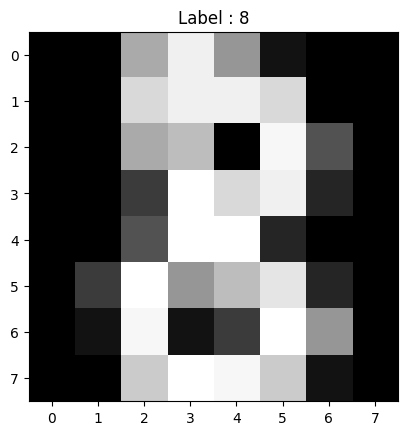

In [6]:
import matplotlib.pyplot as plt

i = 8   # choose any index between 0 and 1796
plt.imshow(digit['images'][i], cmap='Greys_r')
plt.title(f"Label : {digit['target'][i]}")
plt.show()

In [8]:
train_x = digit.data # input variables 
train_y = digit.target # les étiquettes (output variable) 

#découpage du jeu de données (0.25 pour indiquer 25%)

x_train,x_test,y_train,y_test=train_test_split(train_x,train_y,test_size=
0.25, random_state=42)  

I added random_state=42. Without it you get a different split, and a slightly different score, on every run. That makes your results impossible to reproduce.

In [9]:
### Train: 
KNN = KNeighborsClassifier(7) # on utilise 7 voisins 
KNN.fit(x_train, y_train) 

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",7
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.Doesn't affect :meth:`fit` method.",None


In [10]:
### Test: 
print(KNN.score(x_test,y_test)) 

0.9933333333333333


### Q1 a) Validation empirique de K

| K | 1 | 3 | 5 | 7 | 9 | 11 | 15 | 21 |
|---|---|---|---|---|---|---|---|---|
| Accuracy | 0.9822 | 0.9867 | **0.9933** | **0.9933** | 0.9867 | 0.98 | 0.98 | 0.9778 |

- **K = 7 est un bon choix** : meilleure accuracy (99.33 %, ex æquo avec K = 5), soit seulement 3 erreurs sur 450.
- **K petit (K = 1)** : sensible au bruit → **sur-apprentissage** (variance élevée).
- **K grand (K ≥ 11)** : frontières trop lissées → **sous-apprentissage** (biais élevé).
- **Limite** : K a été choisi directement sur le jeu de test, donc le score est optimiste (voir Q1 b).

In [ ]:
for k in [1, 3, 5, 7, 9, 11, 15, 21]:
    s = KNeighborsClassifier(k).fit(x_train, y_train).score(x_test, y_test)
    print(k, round(s, 4))
    

1 0.9822
3 0.9867
5 0.9933
7 0.9933
9 0.9867
11 0.98
15 0.98
21 0.9778


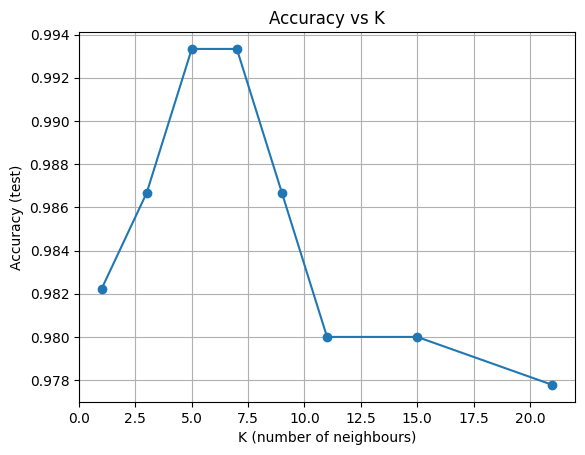

In [12]:
Ks = [1, 3, 5, 7, 9, 11, 15, 21]
scores = [KNeighborsClassifier(k).fit(x_train, y_train).score(x_test, y_test) for k in Ks]
plt.plot(Ks, scores, 'o-')
plt.xlabel('K (number of neighbours)'); plt.ylabel('Accuracy (test)')
plt.title('Accuracy vs K'); plt.grid(True); plt.show()

### Q1 b) Problème et protocole rigoureux

**Problème :** choisir K en maximisant le score sur (x_test, y_test) revient à utiliser le test pour **sélectionner** le modèle → **fuite de données** (data leakage). Le test n'est plus indépendant : le score obtenu est **optimiste** et ne mesure plus la généralisation (sur-apprentissage de l'hyperparamètre sur le test).

**Protocole (5-fold cross-validation) :**
1. Séparer train (75 %) / test (25 %) ; le test est mis de côté.
2. Pour chaque K, découper le **train** en 5 plis : entraîner sur 4, valider sur le 5ᵉ, 5 fois, puis moyenner.
3. Retenir le K ayant le meilleur **score CV moyen**.
4. Réentraîner avec ce K sur tout le train et évaluer **une seule fois** sur le test → score final rapporté.

**Résultat :** meilleur K = … , score test final = …

In [13]:
from sklearn.model_selection import cross_val_score
import numpy as np

Ks = range(1, 22, 2)
cv_means = []
for k in Ks:
    scores = cross_val_score(KNeighborsClassifier(k), x_train, y_train, cv=5)
    cv_means.append(scores.mean())
    print(k, round(scores.mean(), 4), "±", round(scores.std(), 4))

best_k = Ks[int(np.argmax(cv_means))]
final = KNeighborsClassifier(best_k).fit(x_train, y_train)
print("Meilleur K =", best_k, "| Score test final =", round(final.score(x_test, y_test), 4))

1 0.9866 ± 0.0038
3 0.9829 ± 0.0069
5 0.9785 ± 0.0079
7 0.9762 ± 0.008
9 0.9733 ± 0.0089
11 0.9733 ± 0.0083
13 0.9703 ± 0.0091
15 0.9688 ± 0.0098
17 0.9659 ± 0.0129
19 0.9607 ± 0.016
21 0.9562 ± 0.0139
Meilleur K = 1 | Score test final = 0.9822
